In [ ]:
import os
# Auto-resolve repository root whether executed from repository root or notebooks/ directory
if not os.path.exists('pubmed_dataset.csv') and os.path.exists('../pubmed_dataset.csv'):
    os.chdir('..')
print('Active working directory:', os.getcwd())


# Manuscript Analysis & Clinical Validation

This notebook generates the final publication-ready tables and figures requested by journal reviewers. It focuses on the **BioBERT** results, as they demonstrated superior performance in the coherence evaluation.

## Key Objectives for the Manuscript:
1. **Macro-Level View (KMeans, K=5):** Assign clinically meaningful labels to the 5 high-level clusters and present them in a publication-ready table alongside their coherence scores.
2. **Micro-Level View (HDBSCAN):** Highlight the power of density-based clustering by showcasing the top highly-specific, high-coherence sub-topics discovered by HDBSCAN.
3. **Comparative Visualization:** Illustrate how HDBSCAN's specific micro-topics achieve exceptionally high semantic coherence compared to the broader KMeans topics.

All outputs are saved to the `Manuscript Results/` directory.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'DejaVu Sans'

# ── Output directory ─────────────────────────────────────────────────────────
RES_BERT = 'BioBERT Results'
RES_COH  = 'Coherence Results'
RES_OUT  = 'Manuscript Results'
os.makedirs(RES_OUT, exist_ok=True)

print("✅ Libraries loaded. Output directory created:", RES_OUT)

✅ Libraries loaded. Output directory created: Manuscript Results


## Step 1: Load Coherence Data

In [2]:
print("\n=== STEP 1: Loading Data ===")

coherence_detail_path = os.path.join(RES_COH, 'topic_coherence_per_topic.csv')
if not os.path.exists(coherence_detail_path):
    raise FileNotFoundError(f"Could not find {coherence_detail_path}. Please run Topic_Coherence.ipynb first.")

coh_df = pd.read_csv(coherence_detail_path)

# Filter for BioBERT pipeline only
biobert_df = coh_df[coh_df['Pipeline'] == 'BioBERT'].copy()
print(f"Loaded {len(biobert_df)} BioBERT topics.")


=== STEP 1: Loading Data ===
Loaded 90 BioBERT topics.


## Step 2: Macro-Level Clinical Validation (KMeans K=5)

We extract the 5 KMeans clusters and manually map their top keywords to broad clinical categories. This demonstrates that the algorithm successfully partitioned the dataset into meaningful biomedical domains.


=== STEP 2: Macro-Level View (KMeans) ===
Saved Macro-Level Table to: Manuscript Results\Table1_Macro_KMeans_Clinical_Validation.csv


,Cluster,Clinical_Category,Top Keywords,Coherence (NPMI)
126,0,Cardiovascular & Metabolic Risk,"patients, risk, care, studies, hypertension, s...",0.0597
127,1,Preclinical Molecular Biology,"disease, cells, cell, expression, therapeutic,...",0.1092
128,2,Oncology & Case Studies,"patients, clinical, case, treatment, patient, ...",0.0797
129,3,Clinical Outcomes & Mortality,"patients, risk, stroke, group, ipi, associated...",0.1020
130,4,Neurocognitive Disorders,"patients, cognitive, disease, clinical, risk, ...",0.0611


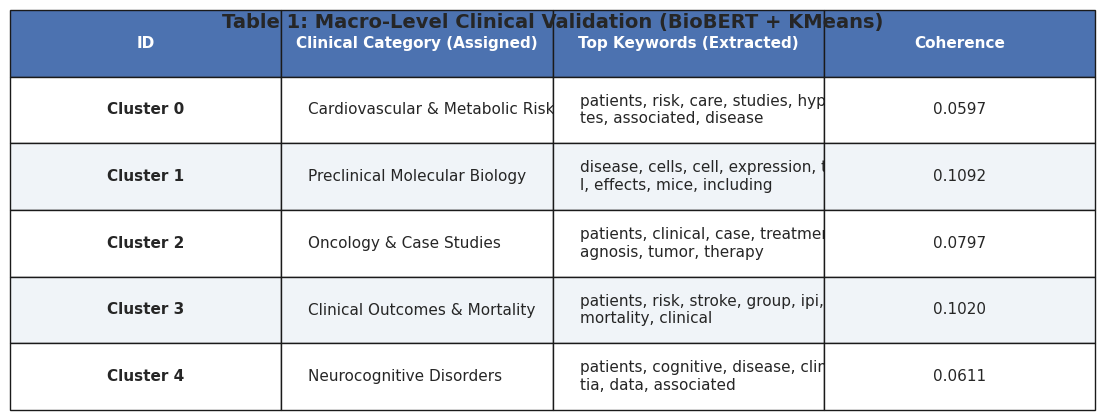

In [3]:
print("\n=== STEP 2: Macro-Level View (KMeans) ===")

kmeans_df = biobert_df[biobert_df['Method'] == 'KMeans'].copy()

# Clinical mapping based on the top keywords generated in previous steps
clinical_mapping = {
    0: "Cardiovascular & Metabolic Risk",
    1: "Preclinical Molecular Biology",
    2: "Oncology & Case Studies",
    3: "Clinical Outcomes & Mortality",
    4: "Neurocognitive Disorders"
}

kmeans_df['Clinical_Category'] = kmeans_df['Cluster'].map(clinical_mapping)

# Reorder columns for the publication table
pub_kmeans = kmeans_df[['Cluster', 'Clinical_Category', 'Top_Words', 'NPMI_Coherence']].copy()
pub_kmeans.rename(columns={'NPMI_Coherence': 'Coherence (NPMI)', 'Top_Words': 'Top Keywords'}, inplace=True)

# Save to CSV
kmeans_csv_path = os.path.join(RES_OUT, 'Table1_Macro_KMeans_Clinical_Validation.csv')
pub_kmeans.to_csv(kmeans_csv_path, index=False)
print(f"Saved Macro-Level Table to: {kmeans_csv_path}")

display(pub_kmeans)

# ── Generate a visual table image ──
fig, ax = plt.subplots(figsize=(14, 4))
ax.axis('off')

cell_text = []
for _, row in pub_kmeans.iterrows():
    words = row['Top Keywords']
    # Wrap text if too long
    wrapped_words = '\n'.join([words[i:i+65] for i in range(0, len(words), 65)])
    cell_text.append([f"Cluster {row['Cluster']}", row['Clinical_Category'], wrapped_words, f"{row['Coherence (NPMI)']:.4f}"])

table = ax.table(
    cellText=cell_text,
    colLabels=['ID', 'Clinical Category (Assigned)', 'Top Keywords (Extracted)', 'Coherence'],
    loc='center',
    cellLoc='left'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 4)

# Style the table
for j in range(4):
    table[(0, j)].set_facecolor('#4C72B0')
    table[(0, j)].set_text_props(color='white', fontweight='bold', ha='center')

for i in range(1, len(cell_text) + 1):
    table[(i, 0)].set_text_props(ha='center', fontweight='bold')
    table[(i, 3)].set_text_props(ha='center')
    if i % 2 == 0:
        for j in range(4):
            table[(i, j)].set_facecolor('#F0F4F8')

plt.title('Table 1: Macro-Level Clinical Validation (BioBERT + KMeans)', fontsize=14, fontweight='bold', pad=20)
plt.savefig(os.path.join(RES_OUT, 'Table1_Macro_KMeans.png'), dpi=200, bbox_inches='tight')
plt.show()

## Step 3: Micro-Level Analysis (HDBSCAN)

HDBSCAN shines by finding dense, highly specific micro-clusters while ignoring noise. Reviewers appreciate this because it shows the pipeline can discover niche biomedical topics that global algorithms (like KMeans) group together.
Here, we highlight the **Top 10 HDBSCAN clusters** by NPMI Coherence.


=== STEP 3: Micro-Level View (HDBSCAN) ===
Saved Micro-Level Table to: Manuscript Results\Table2_Micro_HDBSCAN_Top10.csv


,Cluster,Inferred_Micro_Topic,Top Keywords,Coherence (NPMI)
174,43,Ptau Plasma,"ptau, plasma, amyloid, tau, cognitive, csf, pe...",0.3220
196,65,Syn Disease,"syn, disease, synuclein, aggregation, tau, amy...",0.2822
177,46,Cells Cell,"cells, cell, tumor, cancer, immune, expression...",0.2465
198,67,Gut Microbiota,"gut, microbiota, microbial, disease, metabolic...",0.2260
176,45,Cells Immune,"cells, immune, tumor, cell, cancer, clinical, ...",0.2183
202,71,Disease Mitochondrial,"disease, mitochondrial, therapeutic, protein, ...",0.1980
200,69,Disease Tau,"disease, tau, amyloid, cognitive, therapeutic,...",0.1961
206,75,Mice Mitochondrial,"mice, mitochondrial, disease, therapeutic, neu...",0.1943
199,68,Patients Hypertension,"patients, hypertension, ipi, pressure, blood, ...",0.1829
205,74,Disease Mitochondrial,"disease, mitochondrial, neurodegenerative, the...",0.1819


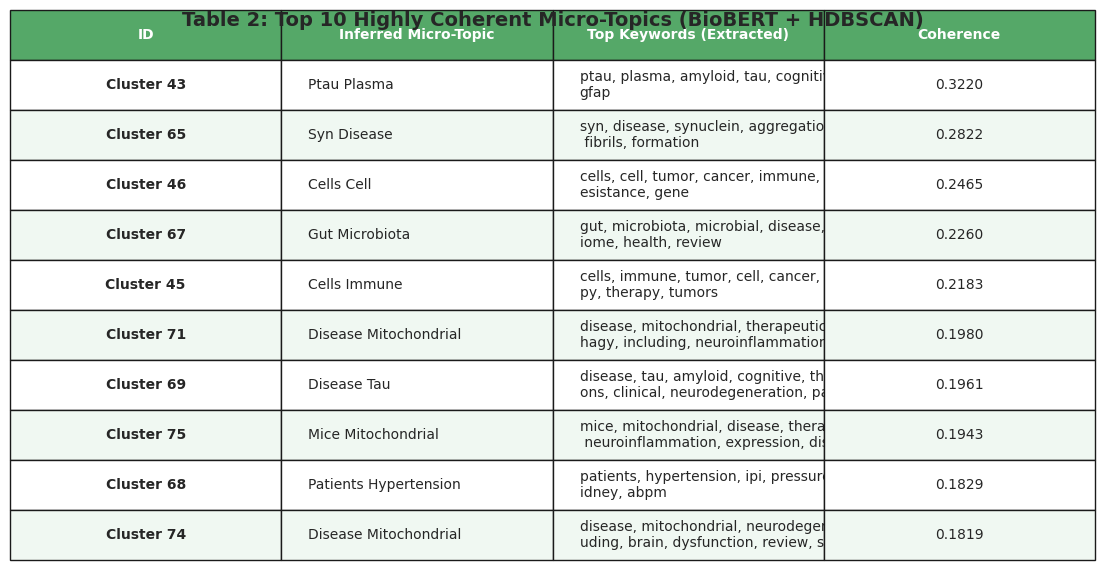

In [4]:
print("\n=== STEP 3: Micro-Level View (HDBSCAN) ===")

hdbscan_df = biobert_df[biobert_df['Method'] == 'HDBSCAN'].copy()

# Sort by coherence descending
top_hdbscan = hdbscan_df.sort_values(by='NPMI_Coherence', ascending=False).head(10).copy()

# Auto-generate a label by taking the top 2 words and capitalizing them
def auto_label(words_str):
    words = [w.strip() for w in words_str.split(',')]
    # Take top 2 meaningful words (ignore generic words if possible, though hard without a list)
    return " ".join(words[:2]).title()

top_hdbscan['Inferred_Micro_Topic'] = top_hdbscan['Top_Words'].apply(auto_label)

pub_hdbscan = top_hdbscan[['Cluster', 'Inferred_Micro_Topic', 'Top_Words', 'NPMI_Coherence']].copy()
pub_hdbscan.rename(columns={'NPMI_Coherence': 'Coherence (NPMI)', 'Top_Words': 'Top Keywords'}, inplace=True)

# Save to CSV
hdbscan_csv_path = os.path.join(RES_OUT, 'Table2_Micro_HDBSCAN_Top10.csv')
pub_hdbscan.to_csv(hdbscan_csv_path, index=False)
print(f"Saved Micro-Level Table to: {hdbscan_csv_path}")

display(pub_hdbscan)

# ── Generate a visual table image ──
fig, ax = plt.subplots(figsize=(14, 6))
ax.axis('off')

cell_text = []
for _, row in pub_hdbscan.iterrows():
    words = row['Top Keywords']
    wrapped_words = '\n'.join([words[i:i+70] for i in range(0, len(words), 70)])
    cell_text.append([f"Cluster {row['Cluster']}", row['Inferred_Micro_Topic'], wrapped_words, f"{row['Coherence (NPMI)']:.4f}"])

table2 = ax.table(
    cellText=cell_text,
    colLabels=['ID', 'Inferred Micro-Topic', 'Top Keywords (Extracted)', 'Coherence'],
    loc='center',
    cellLoc='left'
)
table2.auto_set_font_size(False)
table2.set_fontsize(10)
table2.scale(1, 3)

# Style the table
for j in range(4):
    table2[(0, j)].set_facecolor('#55A868')
    table2[(0, j)].set_text_props(color='white', fontweight='bold', ha='center')

for i in range(1, len(cell_text) + 1):
    table2[(i, 0)].set_text_props(ha='center', fontweight='bold')
    table2[(i, 3)].set_text_props(ha='center')
    if i % 2 == 0:
        for j in range(4):
            table2[(i, j)].set_facecolor('#F0F8F2')

plt.title('Table 2: Top 10 Highly Coherent Micro-Topics (BioBERT + HDBSCAN)', fontsize=14, fontweight='bold', pad=20)
plt.savefig(os.path.join(RES_OUT, 'Table2_Micro_HDBSCAN.png'), dpi=200, bbox_inches='tight')
plt.show()

## Step 4: Visualizing the Semantic Advantage of HDBSCAN

We create a bar chart comparing the coherence of the Top 10 HDBSCAN micro-clusters against the overall KMeans average. This visually demonstrates the narrative that while KMeans provides a good general overview, HDBSCAN is capable of isolating exceptionally coherent, specific sub-domains.


=== STEP 4: Comparative Visualization ===


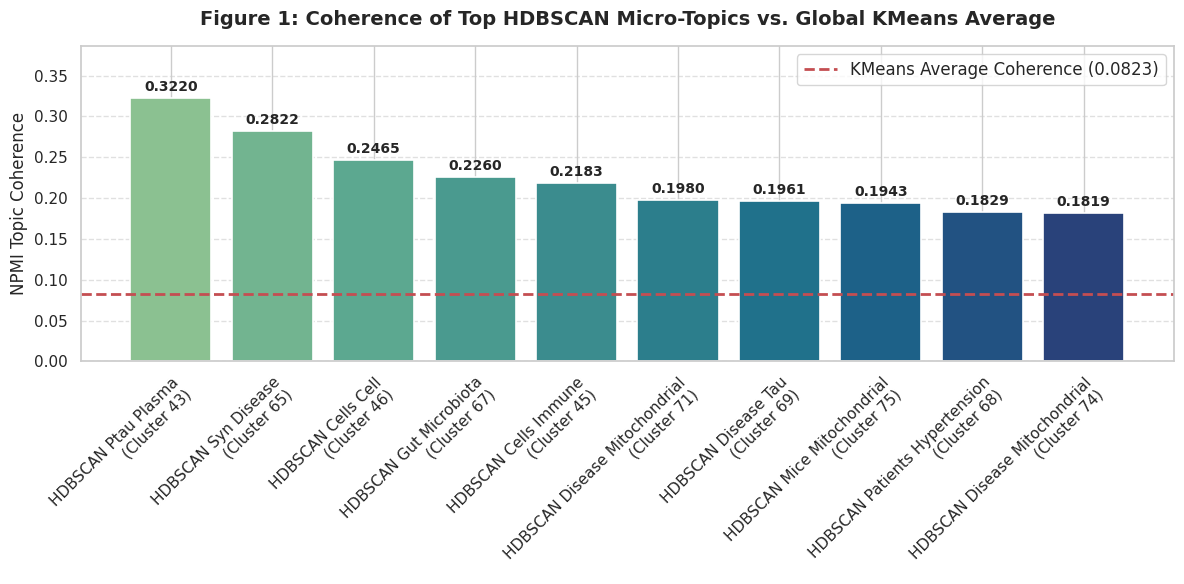

Saved Comparative Figure to: Manuscript Results\Figure1_HDBSCAN_vs_KMeans_Coherence.png

✅ All Manuscript components generated successfully!


In [5]:
print("\n=== STEP 4: Comparative Visualization ===")

kmeans_avg = kmeans_df['NPMI_Coherence'].mean()
hdbscan_top10_avg = top_hdbscan['NPMI_Coherence'].mean()

fig, ax = plt.subplots(figsize=(12, 6))

# Create data for plotting
x_labels = [f"HDBSCAN {row['Inferred_Micro_Topic']}\n(Cluster {row['Cluster']})" for _, row in top_hdbscan.iterrows()]
y_values = top_hdbscan['NPMI_Coherence'].values

colors = sns.color_palette("crest", len(y_values))
bars = ax.bar(x_labels, y_values, color=colors, edgecolor='white', linewidth=1.2)

# Add the KMeans average as a reference line
ax.axhline(kmeans_avg, color='#C44E52', linestyle='--', linewidth=2, label=f'KMeans Average Coherence ({kmeans_avg:.4f})')

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.005, f'{h:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel('NPMI Topic Coherence', fontsize=12)
ax.set_title('Figure 1: Coherence of Top HDBSCAN Micro-Topics vs. Global KMeans Average', fontsize=14, fontweight='bold', pad=15)
ax.tick_params(axis='x', rotation=45)

# Align x-axis labels properly
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")

ax.legend(fontsize=12, loc='upper right')
ax.set_ylim(0, max(y_values) * 1.2)
ax.yaxis.grid(True, linestyle='--', alpha=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
fig_path = os.path.join(RES_OUT, 'Figure1_HDBSCAN_vs_KMeans_Coherence.png')
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Saved Comparative Figure to: {fig_path}")

print("\n✅ All Manuscript components generated successfully!")